# 带方差的折现图

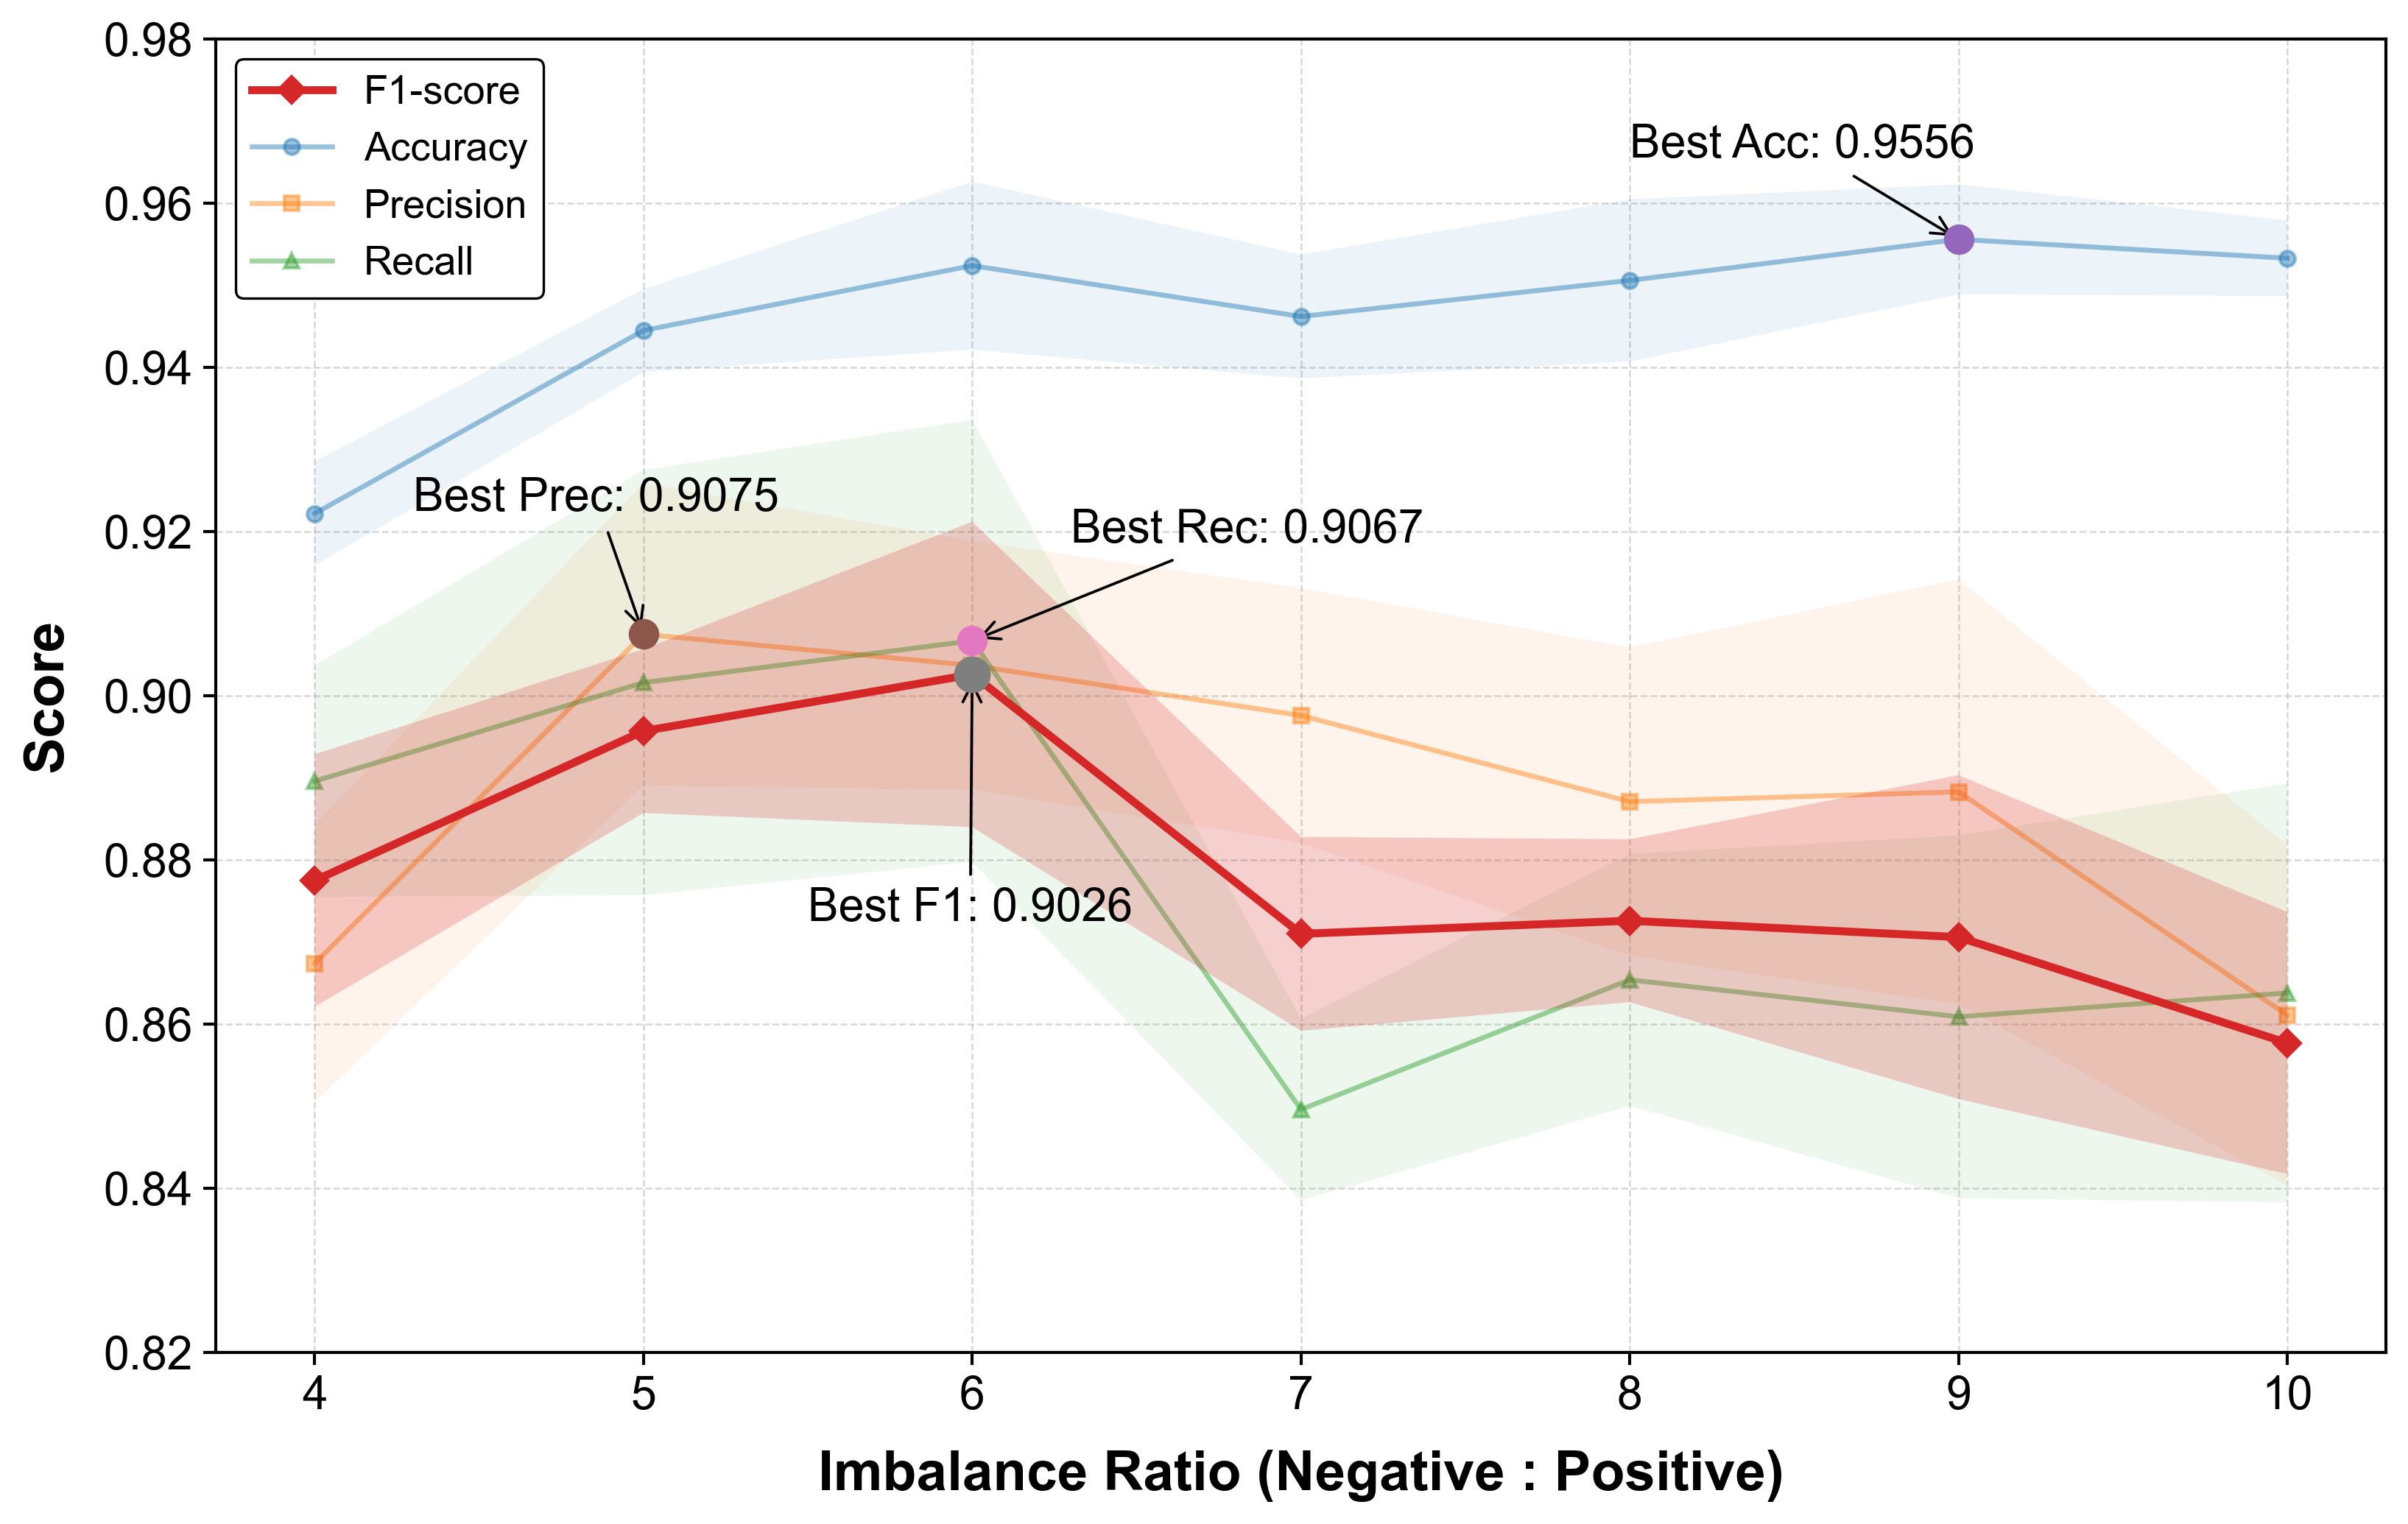

In [1]:
import matplotlib.pyplot as plt
import numpy as np

n_folds = 5

# -----------------------------
# Data
# -----------------------------
x = np.array([4, 5, 6, 7, 8, 9, 10])

accuracy_mean = [0.9307, 0.9222, 0.9445, 0.9524, 0.9462, 0.9506, 0.9556, 0.9533][1:]
accuracy_std  = [0.0187, 0.0142, 0.0113, 0.0229, 0.0169, 0.0221, 0.0150, 0.0103][1:]

precision_mean = [0.9070, 0.8674, 0.9075, 0.9037, 0.8976, 0.8871, 0.8883, 0.8611][1:]
precision_std  = [0.0327, 0.0378, 0.0412, 0.0339, 0.0347, 0.0420, 0.0579, 0.0464][1:]

recall_mean = [0.9073, 0.8896, 0.9016, 0.9067, 0.8496, 0.8654, 0.8609, 0.8638][1:]
recall_std  = [0.0400, 0.0315, 0.0579, 0.0602, 0.0247, 0.0343, 0.0494, 0.0571][1:]

f1_mean = [0.9041, 0.8775, 0.8957, 0.9026, 0.8710, 0.8726, 0.8706, 0.8577][1:]
f1_std  = [0.0294, 0.0344, 0.0223, 0.0416, 0.0264, 0.0222, 0.0441, 0.0357][1:]

accuracy_se  = np.array(accuracy_std) / np.sqrt(n_folds)
precision_se = np.array(precision_std) / np.sqrt(n_folds)
recall_se    = np.array(recall_std) / np.sqrt(n_folds)
f1_se        = np.array(f1_std) / np.sqrt(n_folds)

# -----------------------------
# Font / figure style
# -----------------------------
plt.style.use('default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 30,          # 全局基础字号
    'axes.labelsize': 18,     # 坐标轴标题
    'axes.titlesize': 13,
    'legend.fontsize': 13,  # 图例
    'xtick.labelsize': 15,    # x轴刻度
    'ytick.labelsize': 15,    # y轴刻度
    'figure.dpi': 300,
})

fig, ax = plt.subplots(figsize=(11.6, 7.6))

# -----------------------------
# Plot lines with shaded band
# -----------------------------
def plot_with_shade(ax, x, mean, std, label, marker, is_main=False):
    mean = np.array(mean)
    std = np.array(std)

    if is_main:
        ax.plot(
            x, mean,
            marker=marker,
            linewidth=2.6,
            markersize=6,
            alpha=1.0,
            label=label,
            zorder=4
        )
        ax.fill_between(
            x,
            mean - std,
            mean + std,
            alpha=0.22,
            zorder=3
        )
    else:
        ax.plot(
            x, mean,
            marker=marker,
            linewidth=1.6,
            markersize=5,
            alpha=0.45,
            label=label,
            zorder=2
        )
        ax.fill_between(
            x,
            mean - std,
            mean + std,
            alpha=0.08,
            zorder=1
        )

plot_with_shade(ax, x, accuracy_mean, accuracy_se, 'Accuracy', 'o', is_main=False)
plot_with_shade(ax, x, precision_mean, precision_se, 'Precision', 's', is_main=False)
plot_with_shade(ax, x, recall_mean, recall_se, 'Recall', '^', is_main=False)
plot_with_shade(ax, x, f1_mean, f1_se, 'F1-score', 'D', is_main=True)

# -----------------------------
# Axes styling
# -----------------------------
ax.set_xticks(x)
ax.set_xlabel('Imbalance Ratio (Negative : Positive)', fontweight='bold', labelpad=10)
ax.set_ylabel('Score', fontweight='bold', labelpad=10)

ax.set_ylim(0.82, 0.98)

# 保持你原来的网格样式不变
ax.grid(True, linestyle='--', linewidth=0.6, alpha=0.5)
ax.set_axisbelow(True)

# 四周边框
for spine in ax.spines.values():
    spine.set_linewidth(1.0)

# 刻度只调线宽/长度，字号由 rcParams 控制
ax.tick_params(axis='both', which='major', width=1.0, length=4)

# 图例：把 F1 放到第一位
handles, labels = ax.get_legend_handles_labels()
order = [labels.index('F1-score')] + [i for i in range(len(labels)) if labels[i] != 'F1-score']

legend = ax.legend(
    [handles[i] for i in order],
    [labels[i] for i in order],
    loc='best',
    frameon=True,
    framealpha=1.0,
    edgecolor='black'
)
legend.get_frame().set_linewidth(0.8)

# -----------------------------
# Highlight best point of each line
# -----------------------------
def annotate_best(ax, x, y, label, dx, dy, is_main=False):
    y = np.array(y)
    best_idx = np.argmax(y)
    best_x = x[best_idx]
    best_y = y[best_idx]

    point_size = 120 if is_main else 80
    ann_fontsize = 15

    ax.scatter(best_x, best_y, s=point_size, zorder=6)
    ax.annotate(
        f'Best {label}: {best_y:.4f}',
        xy=(best_x, best_y),
        xytext=(best_x + dx, best_y + dy),
        arrowprops=dict(arrowstyle='->', lw=0.9),
        fontsize=ann_fontsize,
        fontweight='normal'
    )

annotate_best(ax, x, accuracy_mean,  'Acc',  -1.0,  0.010, is_main=False)
annotate_best(ax, x, precision_mean, 'Prec', -0.7,  0.015, is_main=False)
annotate_best(ax, x, recall_mean,    'Rec',   0.3,  0.012, is_main=False)
annotate_best(ax, x, f1_mean,        'F1',   -0.5, -0.030, is_main=True)

# -----------------------------
# Layout and save
# -----------------------------
plt.tight_layout()
# plt.savefig('ratio_comparison_lineplot.png', dpi=600, bbox_inches='tight')
# plt.savefig('ratio_comparison_lineplot.pdf', bbox_inches='tight')
plt.show()

# 另一种形式的带方差的折现图

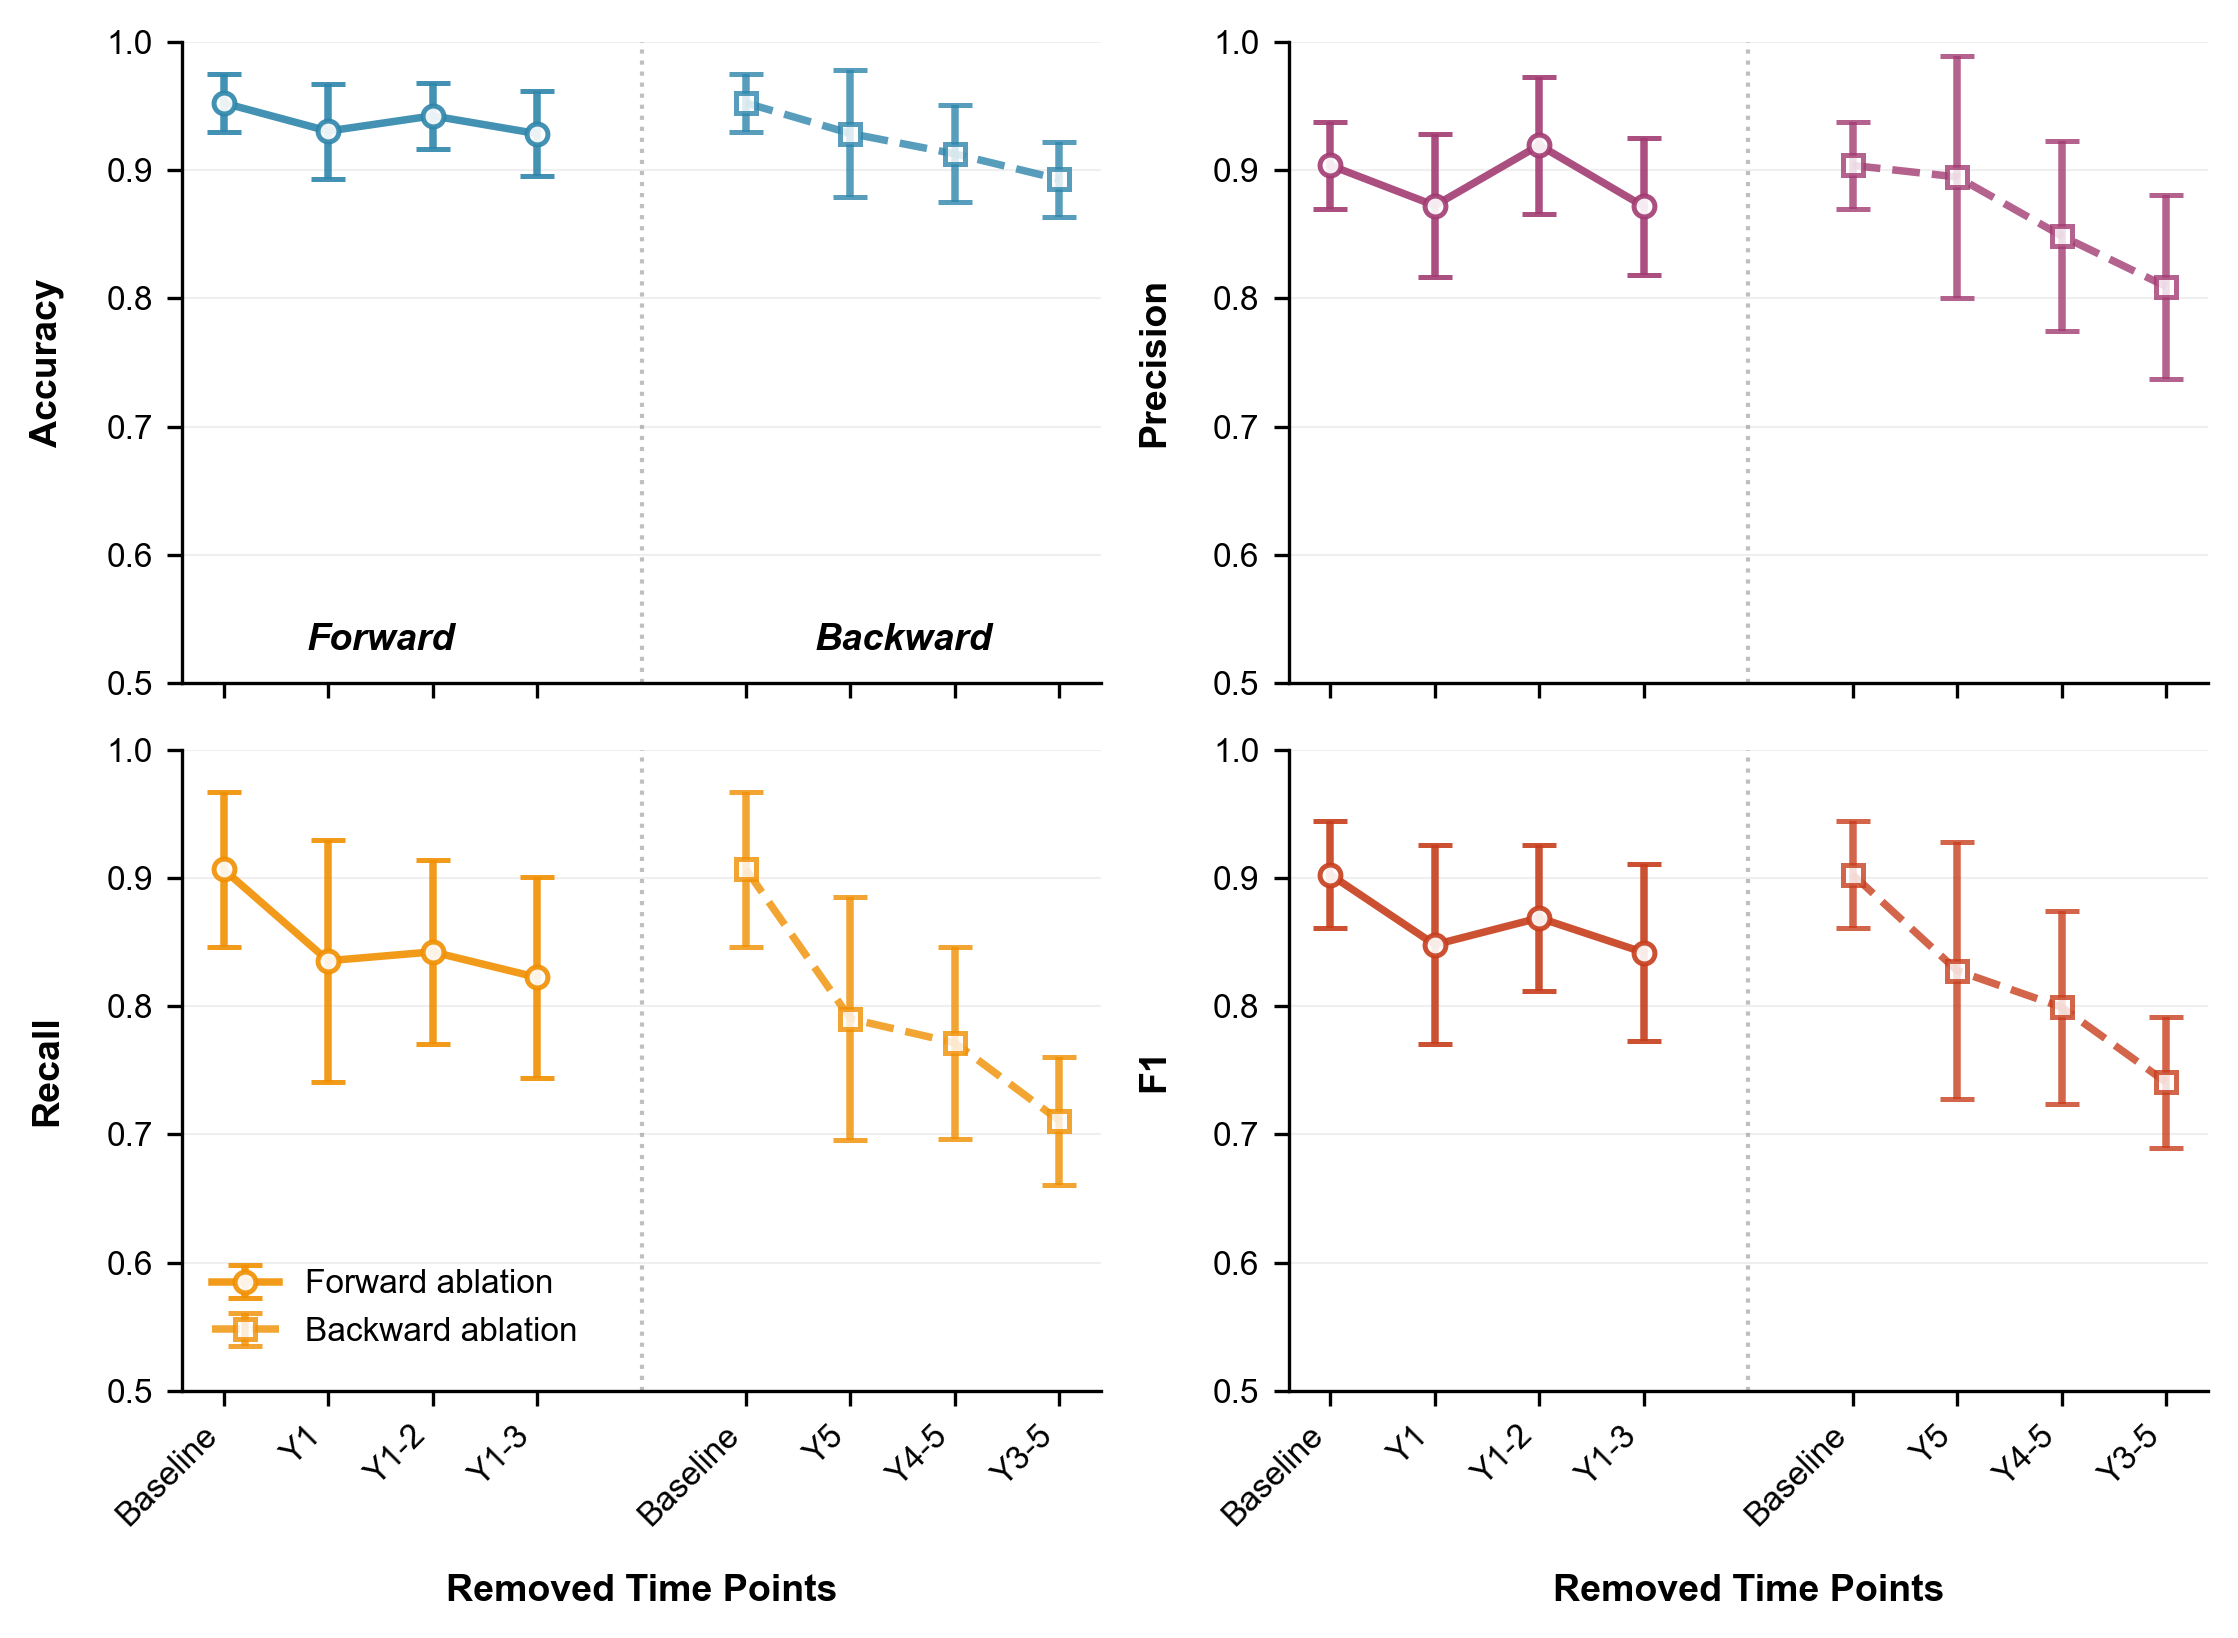

In [2]:
import matplotlib.pyplot as plt
from matplotlib import rcParams

plt.style.use('default')
rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica'],
    'font.size': 8,
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'legend.fontsize': 8,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'figure.dpi': 300,
    'figure.figsize': (7.5, 5.5),
    'lines.linewidth': 1.5,
    'lines.markersize': 5,
    'errorbar.capsize': 3
})

conditions_forward = ['Baseline', 'Remove Y1', 'Remove Y1-2', 'Remove Y1-3']
conditions_backward = ['Baseline', 'Remove Y5', 'Remove Y4-5', 'Remove Y3-5']

# 均值数据
accuracy = [0.9524, 0.9305, 0.9424, 0.9285, 0.9286, 0.9127, 0.8929]
precision = [0.9037, 0.8724, 0.9195, 0.8717, 0.8947, 0.8487, 0.8092]
recall = [0.9067, 0.8355, 0.8424, 0.8225, 0.7902, 0.7714, 0.7106]
f1 = [0.9026, 0.8480, 0.8689, 0.8419, 0.8277, 0.7992, 0.7406]

# 标准差数据
accuracy_std = [0.0229, 0.0371, 0.0258, 0.0333, 0.0493, 0.0379, 0.0291]
precision_std = [0.0339, 0.0557, 0.0535, 0.0531, 0.0947, 0.0738, 0.0718]
recall_std = [0.0602, 0.0945, 0.0718, 0.0782, 0.0947, 0.0749, 0.0500]
f1_std = [0.0416, 0.0775, 0.0570, 0.0689, 0.1002, 0.0754, 0.0510]


def plot_ablation_comparison_with_baseline_both_sides():
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(7.5, 5.5))
    axes = [ax1, ax2, ax3, ax4]
    metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
    colors = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D']

    # 定义x轴位置，Forward和Backward各有4个点（包括Baseline）
    x_positions_forward = [0, 1, 2, 3]  # Forward ablation + Baseline
    x_positions_backward = [5, 6, 7, 8]  # Backward ablation + Baseline

    # 对应的条件标签
    x_ticks = [0, 1, 2, 3, 5, 6, 7, 8]
    x_tick_labels = ['Baseline', 'Y1', 'Y1-2', 'Y1-3',
                     'Baseline', 'Y5', 'Y4-5', 'Y3-5']

    for i, (ax, metric, color) in enumerate(zip(axes, metrics, colors)):
        # 提取数据
        values = [accuracy, precision, recall, f1][i]
        stds = [accuracy_std, precision_std, recall_std, f1_std][i]

        # 前向消融数据（包括基线）
        forward_values = [values[0], values[1], values[2], values[3]]
        forward_stds = [stds[0], stds[1], stds[2], stds[3]]

        # 后向消融数据（也包括基线）
        backward_values = [values[0], values[4], values[5], values[6]]
        backward_stds = [stds[0], stds[4], stds[5], stds[6]]

        # 绘制前向消融（实线）
        ax.errorbar(x_positions_forward, forward_values,
                    yerr=forward_stds, fmt='o-', color=color,
                    alpha=0.9, label='Forward ablation',
                    capsize=4, capthick=1, markersize=5, linewidth=1.8,
                    markerfacecolor='white', markeredgewidth=1.2)

        # 绘制后向消融（虚线，与前向断开）
        ax.errorbar(x_positions_backward, backward_values,
                    yerr=backward_stds, fmt='s--', color=color,
                    alpha=0.8, label='Backward ablation',
                    capsize=4, capthick=1, markersize=5, linewidth=1.8,
                    markerfacecolor='white', markeredgewidth=1.2)

        # 设置y轴标签和范围
        ax.set_ylabel(metric, fontweight='bold', labelpad=10)

        # 根据指标调整y轴范围
        # if metric == 'Accuracy' or metric == 'Precision':
        #     ax.set_ylim(0.65, 1.0)
        # else:
        ax.set_ylim(0.5, 1)

        # 设置x轴
        ax.set_xticks(x_ticks)
        if i >= 2:  # 只有底部子图显示详细的x轴标签
            ax.set_xticklabels(x_tick_labels, rotation=45, ha='right')
            ax.set_xlabel('Removed Time Points', fontweight='bold', labelpad=10)
        else:
            ax.set_xticklabels([''] * len(x_ticks))

        ax.grid(True, alpha=0.2, axis='y', linestyle='-', linewidth=0.5)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        # 在Forward和Backward之间添加垂直分隔线
        ax.axvline(x=4, color='gray', linestyle=':', alpha=0.5, linewidth=1)

        # 添加分区标签
        if i == 0:  # 只在第一个子图添加分区标签
            ax.text(1.5, ax.get_ylim()[0] + 0.02, 'Forward', ha='center', va='bottom',
                    fontsize=9, fontweight='bold', style='italic', backgroundcolor='white')
            ax.text(6.5, ax.get_ylim()[0] + 0.02, 'Backward', ha='center', va='bottom',
                    fontsize=9, fontweight='bold', style='italic', backgroundcolor='white')

        # 在每个数据点上添加数值标注
        # for j, (x, y, std) in enumerate(zip(x_positions_forward, forward_values, forward_stds)):
        #     ax.text(x, y + std + 0.01, f'{y:.3f}', ha='center', va='bottom', fontsize=6)
        # for j, (x, y, std) in enumerate(zip(x_positions_backward, backward_values, backward_stds)):
        #     ax.text(x, y + std + 0.01, f'{y:.3f}', ha='center', va='bottom', fontsize=6)

    ax3.legend(frameon=False, loc='lower left', bbox_to_anchor=(0, 0.02))


    plt.tight_layout()
    # # 保存图片
    # plt.savefig('ablation_study_with_gap.pdf', dpi=300,
    #             bbox_inches='tight', facecolor='white', edgecolor='none')
    plt.show()

plot_ablation_comparison_with_baseline_both_sides()
